# 逻辑回归预测芯片质量通过

任务：

    1、基于chip_ test.csv数据，建立逻辑回归模型（二阶边界)，评估模型表现；
    2、以函数的方式求解边界曲线
    3、描绘出完整的決策边界曲线

In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from matplotlib import pyplot as plt

In [2]:
data = pd.read_csv('chip_test.csv')
data.head()

,test1,test2,pass
0,0.051267,0.69956,1
1,-0.092742,0.68494,1
2,-0.213710,0.69225,1
3,-0.375000,0.50219,1
4,0.183760,0.93348,0


In [3]:
mask = data.loc[:,'pass']==1
~mask

0      False
1      False
2      False
3      False
4       True
       ...  
113     True
114     True
115     True
116     True
117     True
Name: pass, Length: 118, dtype: bool

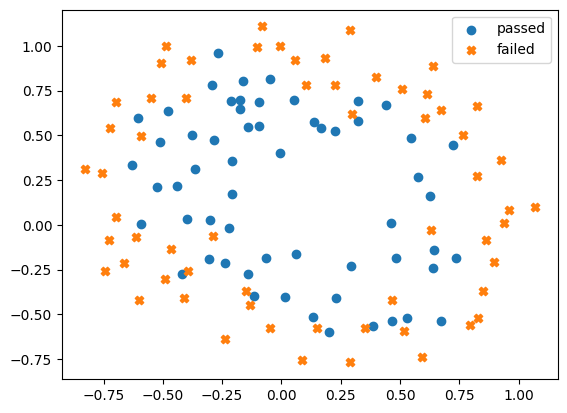

In [4]:
fig1 = plt.figure()
passed = plt.scatter(data.loc[:,'test1'][mask],data.loc[:,'test2'][mask])
failed = plt.scatter(data.loc[:,'test1'][~mask],data.loc[:,'test2'][~mask],marker='X')
plt.legend((passed,failed),('passed','failed'))
plt.show()

In [5]:
x1 = data.loc[:,'test1']
x2 = data.loc[:,'test2']
y = data.loc[:,'pass']
x_new_dic = {'x1':x1,'x2':x2,'x1_2':x1**2,'x2_2':x2**2,'x1_x2':x1*x2}
x_new = pd.DataFrame(x_new_dic)
lr = LogisticRegression()
lr.fit(x_new,y)

LogisticRegression()

In [6]:
y_predict = lr.predict(x_new)
a_s = accuracy_score(y,y_predict)
a_s

0.8135593220338984

In [7]:
lr.coef_

array([[ 0.35014646,  0.67136871, -2.78152986, -2.39046083, -0.95686114]])

In [8]:
theta1,theta2,theta3,theta4,theta5 = lr.coef_[0]
theta0 = lr.intercept_[0]
theta0,theta1,theta2,theta3,theta4,theta5

(1.1994699484027331,
 0.3501464610494277,
 0.6713687123833847,
 -2.7815298580915706,
 -2.3904608348076812,
 -0.9568611386972844)

In [9]:
# theta0+theta1*x1+theta2*x2+theta3*x1**2+theta4*x2**2+theta5*x1*x2 = 0
# theta4*x2**2 + (theta5*x1+theta2)*x2 + (theta0+theta1*x1+theta3*x1**2) = 0
def new_x2(x1):
    a = theta4
    b = theta5*x1+theta2
    c = theta0+theta1*x1+theta3*x1*x1
    pos_x2_new = (-b+np.sqrt(b**2-4*a*c))/(2*a)
    nei_x2_new = (-b-np.sqrt(b**2-4*a*c))/(2*a)
    return pos_x2_new,nei_x2_new

/var/folders/by/j0bmq4zn13j76bgl28j62dkr0000gn/T/ipykernel_4397/133144575.py:7: RuntimeWarning: invalid value encountered in sqrt
  pos_x2_new = (-b+np.sqrt(b**2-4*a*c))/(2*a)
/var/folders/by/j0bmq4zn13j76bgl28j62dkr0000gn/T/ipykernel_4397/133144575.py:8: RuntimeWarning: invalid value encountered in sqrt
  nei_x2_new = (-b-np.sqrt(b**2-4*a*c))/(2*a)


<Figure size 640x480 with 0 Axes>

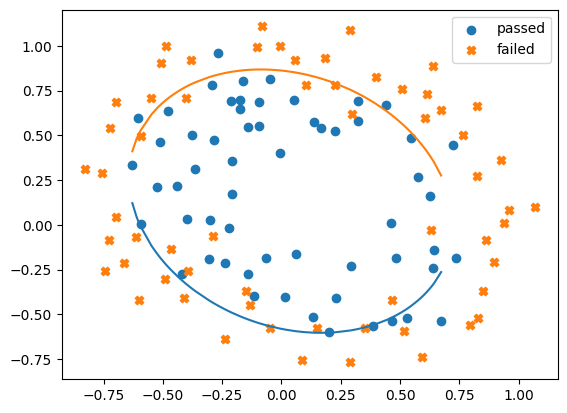

In [10]:
fig3 = plt.figure()

x1 = x1.sort_values()
pos_x2_new = []
nei_x2_new = []

for x in x1:
    pos_x2_new.append(new_x2(x)[0])
    nei_x2_new.append(new_x2(x)[1])
fig2 = plt.figure()
plt.plot(x1,pos_x2_new)
plt.plot(x1,nei_x2_new)
passed = plt.scatter(data.loc[:,'test1'][mask],data.loc[:,'test2'][mask])
failed = plt.scatter(data.loc[:,'test1'][~mask],data.loc[:,'test2'][~mask],marker='X')
plt.legend((passed,failed),('passed','failed'))
plt.show()

In [11]:
# 扩展x1的值，使图形连接起来
x1_extend = [-0.7+x/10000 for x in range(0,190000)]
x1_extend = np.array(x1_extend)
x1_extend

array([-0.7   , -0.6999, -0.6998, ..., 18.2997, 18.2998, 18.2999])

/var/folders/by/j0bmq4zn13j76bgl28j62dkr0000gn/T/ipykernel_4397/133144575.py:7: RuntimeWarning: invalid value encountered in sqrt
  pos_x2_new = (-b+np.sqrt(b**2-4*a*c))/(2*a)
/var/folders/by/j0bmq4zn13j76bgl28j62dkr0000gn/T/ipykernel_4397/133144575.py:8: RuntimeWarning: invalid value encountered in sqrt
  nei_x2_new = (-b-np.sqrt(b**2-4*a*c))/(2*a)


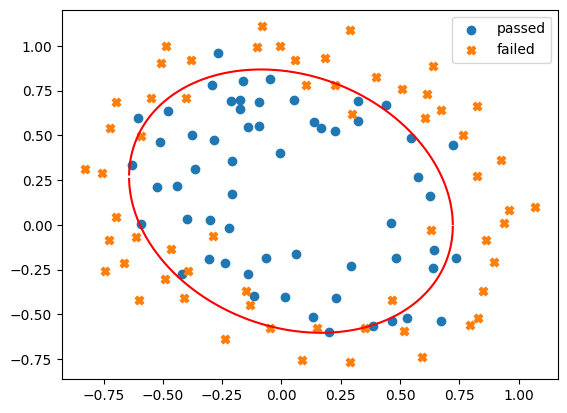

In [13]:
pos_x2_extend,nei_x2_extend = new_x2(x1_extend)

fig3 = plt.figure()
plt.plot(x1_extend,pos_x2_extend,'r')
plt.plot(x1_extend,nei_x2_extend,'r')
passed = plt.scatter(data.loc[:,'test1'][mask],data.loc[:,'test2'][mask])
failed = plt.scatter(data.loc[:,'test1'][~mask],data.loc[:,'test2'][~mask],marker='X')
plt.legend((passed,failed),('passed','failed'))

plt.show()